# 03 · Random Forest en las tres variables objetivo

**Proyecto:** Predicción del riesgo y la gravedad de accidentes en carreteras del Perú con datos abiertos y clima
(IA Aplicada 1INF62, PUCP 2026-2). **Issue #11.** Respaldo: Muñoz et al. (2024), que usan Random Forest para la
gravedad de los accidentes.

Mismos datos, variables, validación y métricas que el baseline (`02_modelos.ipynb`):

| Variable objetivo | Random Forest | Se compara con | Métrica principal |
|---|---|---|---|
| `N_ACC` | `M.rf_conteo` (criterio de **Poisson**) | Ingenuo media 28 días y Poisson | D² de Poisson |
| `HAY_FATAL` | `M.random_forest(class_weight=None)`: sin pesos, para que las probabilidades queden calibradas | Ingenuo fatales 28 días y logística | PR-AUC |
| `GRAVEDAD` | `M.random_forest` con pesos de clase (`balanced_subsample` o `balanced`, se elige en la CV) | Dummy, Modelo 2 del avance y logística multinomial | Macro-F1 |

**Ajuste de hiperparámetros:** `RandomizedSearchCV` con 20 combinaciones por variable objetivo
(grillas del issue #2: `min_samples_leaf` 5–80, `max_features` 0.2–0.8, `max_depth` None/8/12/20).
- **Tarea 1:** los 5 pliegues de origen móvil sobre el train (`E.cv_temporal`). El holdout abr–sep 2021 se usa una vez, al final.
- **Tarea 2:** `E.CV` **solo sobre el 80 % de entrenamiento**; la comparación usa los 25 pliegues de `E.CV_REPETIDA`.

Se reporta el RF con sus valores por defecto de `src/models.py` y el ajustado.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import models as M, evaluation as E

warnings.filterwarnings("ignore")
PLOTS = ROOT / "results" / "plots"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FILAS = []   # filas nuevas de results/metrics.csv (solo las del RF)
N_ITER = 20


def guardar(fig, nombre):
    fig.savefig(PLOTS / nombre, bbox_inches="tight")
    plt.show()


def resumen(res):
    return pd.DataFrame({k: v.agg(["mean", "std"]).T.stack() for k, v in res.items()}).T.round(4)


def config(params):
    return ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items())


def ajustar(modelo, grilla, X, y, cv, scoring):
    """Búsqueda aleatoria. Devuelve el modelo con la mejor configuración (sin reentrenar), sus parámetros y la tabla."""
    t = time.time()
    rs = RandomizedSearchCV(modelo, grilla, n_iter=N_ITER, scoring=scoring, cv=cv, n_jobs=-1, refit=False,
                            random_state=M.SEED).fit(X, y)
    tabla = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]]
    tabla["params"] = tabla.params.map(config)
    print(f"{N_ITER} configuraciones en {time.time() - t:.0f} s · mejor: {config(rs.best_params_)}")
    display(tabla.head(5).round(4))
    return clone(modelo).set_params(**rs.best_params_), rs.best_params_, tabla

## 1. Tarea 1 · Pronóstico de riesgo (panel departamento × día)

In [2]:
panel = M.cargar_panel()
tr1 = panel[panel.FECHA < M.INICIO_HOLDOUT].reset_index(drop=True)
te1 = panel[panel.FECHA >= M.INICIO_HOLDOUT].reset_index(drop=True)
COLS1 = M.columnas(M.GRUPOS_T1)
X1 = COLS1[0] + COLS1[1]
FOLDS1 = list(E.cv_temporal(tr1.FECHA))
print(f"Train: {len(tr1):,} filas · holdout: {len(te1):,} filas")

Train: 10,776 filas · holdout: 4,392 filas


### 1.1 Conteo de accidentes (`N_ACC`)
Criterio de partición de Poisson (minimiza la devianza de Poisson en cada nodo). Se ajusta por devianza de Poisson
media en los 5 pliegues temporales.

In [3]:
grilla = {"reg__min_samples_leaf": [5, 10, 20, 40, 80],
          "reg__max_features": [0.2, 0.35, 0.5, 0.65, 0.8],
          "reg__max_depth": [None, 8, 12, 20]}
rf1, P1, T1 = ajustar(M.rf_conteo(COLS1), grilla, tr1[X1], tr1.N_ACC, FOLDS1, "neg_mean_poisson_deviance")

20 configuraciones en 112 s · mejor: min_samples_leaf=20, max_features=0.2, max_depth=20


,params,mean_test_score,std_test_score
17,"min_samples_leaf=20, max_features=0.2, max_dep...",-0.9537,0.0665
1,"min_samples_leaf=40, max_features=0.2, max_dep...",-0.9544,0.0665
0,"min_samples_leaf=40, max_features=0.35, max_de...",-0.9547,0.0663
16,"min_samples_leaf=10, max_features=0.2, max_dep...",-0.9556,0.0677
5,"min_samples_leaf=80, max_features=0.5, max_dep...",-0.9558,0.0656


In [4]:
ingenuo_conteo = lambda df, col: df[col].fillna(df.N_ACC_M7)
res1 = {"Ingenuo · media 28 días": pd.DataFrame([E.metricas_conteo(tr1.N_ACC.iloc[b], ingenuo_conteo(tr1.iloc[b], "N_ACC_M28")) for _, b in FOLDS1]),
        "Baseline · Poisson": E.cv_puntajes(M.poisson(COLS1), tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo),
        "Random Forest (por defecto)": E.cv_puntajes(M.rf_conteo(COLS1), tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo),
        "Random Forest (ajustado)": E.cv_puntajes(rf1, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)}
display(resumen(res1))
print("RF − Poisson (D²):       ", E.comparacion_pareada(res1["Random Forest (ajustado)"].d2_poisson, res1["Baseline · Poisson"].d2_poisson))
print("RF − media 28 días (D²): ", E.comparacion_pareada(res1["Random Forest (ajustado)"].d2_poisson, res1["Ingenuo · media 28 días"].d2_poisson))
print("Nota: la configuración se eligió con estos mismos pliegues, así que el CV del RF ajustado es algo optimista; el holdout no.")

pred_pois = clone(M.poisson(COLS1)).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
pred_rf1 = clone(rf1).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
hold1 = {"Ingenuo · media 28 días": E.metricas_conteo(te1.N_ACC, ingenuo_conteo(te1, "N_ACC_M28")),
         "Baseline · Poisson": E.metricas_conteo(te1.N_ACC, pred_pois),
         "Random Forest (ajustado)": E.metricas_conteo(te1.N_ACC, pred_rf1)}
display(pd.DataFrame(hold1).T.round(4))
for nombre in ("Random Forest (por defecto)", "Random Forest (ajustado)"):
    FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": nombre, "validacion": "CV temporal (5 pliegues)", **res1[nombre].mean().to_dict()})
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": "Random Forest (ajustado)", "validacion": "holdout abr-sep 2021", **hold1["Random Forest (ajustado)"]})

poisson_dev         d2_poisson             mae  \
                                   mean     std       mean     std    mean   
Ingenuo · media 28 días          0.9984  0.0469     0.2173  0.0525  0.5464   
Baseline · Poisson               0.9489  0.0529     0.2562  0.0535  0.5685   
Random Forest (por defecto)      0.9600  0.0747     0.2495  0.0285  0.5695   
Random Forest (ajustado)         0.9537  0.0743     0.2544  0.0285  0.5662   

                                       rmse          
                                std    mean     std  
Ingenuo · media 28 días      0.0623  0.7892  0.0802  
Baseline · Poisson           0.0339  0.7923  0.0584  
Random Forest (por defecto)  0.0579  0.7919  0.0831  
Random Forest (ajustado)     0.0569  0.7880  0.0825

RF − Poisson (D²):        -0.002 (IC95% aprox. -0.029 a +0.025), mejor en 1 de 5 pliegues
RF − media 28 días (D²):  +0.037 (IC95% aprox. +0.011 a +0.064), mejor en 5 de 5 pliegues
Nota: la configuración se eligió con estos mismos pliegues, así que el CV del RF ajustado es algo optimista; el holdout no.


,poisson_dev,d2_poisson,mae,rmse
Ingenuo · media 28 días,1.0019,0.2775,0.6046,0.8365
Baseline · Poisson,1.0170,0.2665,0.5896,0.8504
Random Forest (ajustado),0.9799,0.2933,0.6093,0.8366


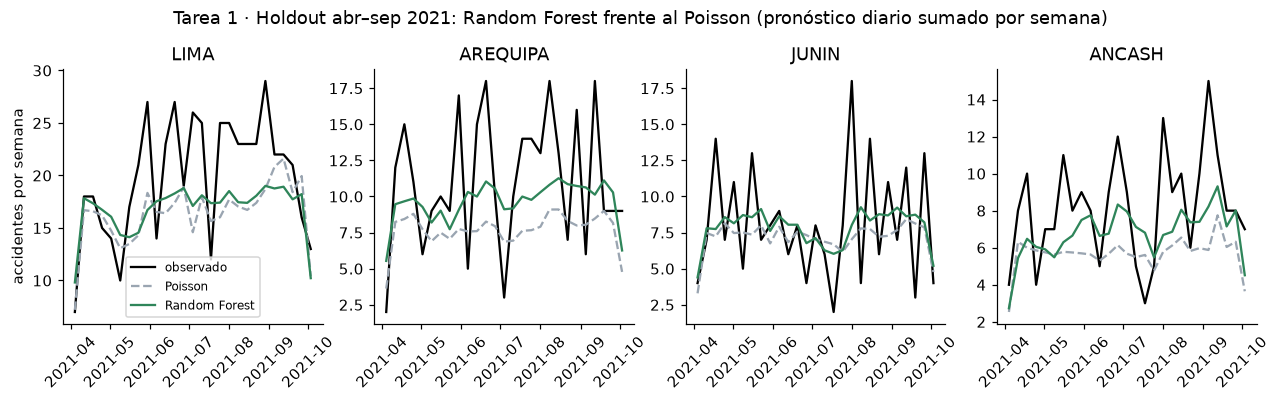

In [5]:
top = panel.groupby("DEPARTAMENTO").N_ACC.sum().nlargest(4).index
sem = te1.assign(POIS=pred_pois, RF=pred_rf1).groupby(["DEPARTAMENTO", pd.Grouper(key="FECHA", freq="W")])[["N_ACC", "POIS", "RF"]].sum()
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, d in zip(axs, top):
    s = sem.loc[d]
    ax.plot(s.index, s.N_ACC, "k-", lw=1.5, label="observado")
    ax.plot(s.index, s.POIS, "--", color="#9aa5b1", label="Poisson")
    ax.plot(s.index, s.RF, "-", color="#2f855a", label="Random Forest")
    ax.set_title(d); ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("accidentes por semana"); axs[0].legend(fontsize=8)
fig.suptitle("Tarea 1 · Holdout abr–sep 2021: Random Forest frente al Poisson (pronóstico diario sumado por semana)", y=1.06)
guardar(fig, "modelo_04_t1_conteo_rf_holdout.png")

### 1.2 ¿Habrá algún accidente fatal mañana? (`HAY_FATAL`)
RF sin pesos de clase, para no descalibrar las probabilidades. Criterio: PR-AUC media en los pliegues temporales.
Además de la curva precisión–recall se grafica la curva de calibración (¿la probabilidad sirve para repartir recursos?).

In [6]:
grilla = {"clf__min_samples_leaf": [5, 10, 20, 40, 80],
          "clf__max_features": [0.2, 0.35, 0.5, 0.65, 0.8],
          "clf__max_depth": [None, 8, 12, 20]}
rf1b, P1b, T1b = ajustar(M.random_forest(COLS1, class_weight=None), grilla, tr1[X1], tr1.HAY_FATAL, FOLDS1, "average_precision")

20 configuraciones en 151 s · mejor: min_samples_leaf=40, max_features=0.35, max_depth=8


,params,mean_test_score,std_test_score
13,"min_samples_leaf=40, max_features=0.35, max_de...",0.1395,0.0169
17,"min_samples_leaf=20, max_features=0.2, max_dep...",0.1391,0.0168
4,"min_samples_leaf=80, max_features=0.65, max_de...",0.1379,0.0147
10,"min_samples_leaf=40, max_features=0.65, max_de...",0.1378,0.0146
5,"min_samples_leaf=80, max_features=0.5, max_dep...",0.1377,0.0134


pr_auc         roc_auc           brier  \
                                     mean     std    mean     std    mean   
Ingenuo · fatales últimos 28 días  0.1119  0.0178  0.6775  0.0140  0.0542   
Baseline · Reg. logística          0.1330  0.0279  0.7041  0.0254  0.0561   
Random Forest (por defecto)        0.1357  0.0168  0.7094  0.0133  0.0537   
Random Forest (ajustado)           0.1395  0.0189  0.7162  0.0123  0.0532   

                                          prevalencia          
                                      std        mean     std  
Ingenuo · fatales últimos 28 días  0.0067      0.0584  0.0081  
Baseline · Reg. logística          0.0076      0.0584  0.0081  
Random Forest (por defecto)        0.0066      0.0584  0.0081  
Random Forest (ajustado)           0.0067      0.0584  0.0081

RF − logística (PR-AUC):  +0.006 (IC95% aprox. -0.020 a +0.033), mejor en 2 de 5 pliegues
RF − ingenuo (PR-AUC):    +0.028 (IC95% aprox. +0.017 a +0.038), mejor en 5 de 5 pliegues
RF − logística (Brier):   -0.003 (IC95% aprox. -0.008 a +0.002), mejor en 3 de 5 pliegues


,pr_auc,roc_auc,brier,prevalencia
Ingenuo · fatales últimos 28 días,0.1313,0.6887,0.0618,0.0676
Baseline · Reg. logística,0.1612,0.7335,0.0600,0.0676
Random Forest (ajustado),0.1583,0.7245,0.0602,0.0676


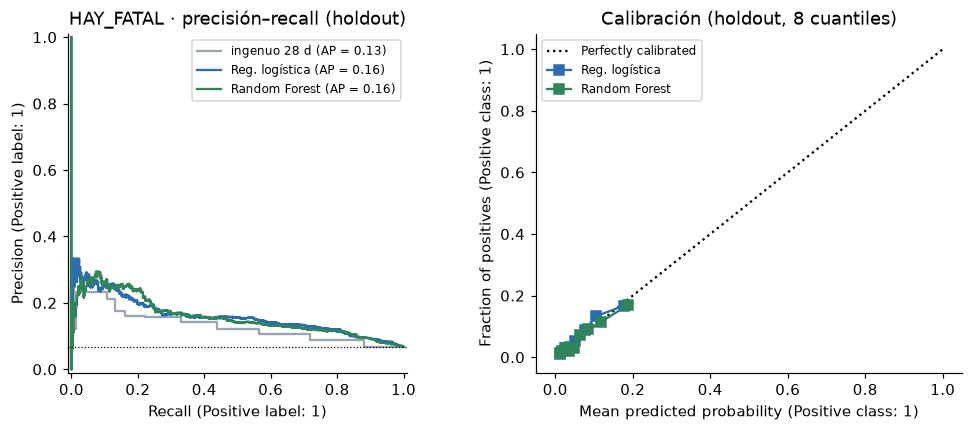

In [7]:
ingenuo_fatal = lambda df: 1 - np.exp(-df.N_FATALES_M28)
logit1 = M.logit(COLS1, class_weight=None)
res1b = {"Ingenuo · fatales últimos 28 días": pd.DataFrame([E.metricas_binaria(tr1.HAY_FATAL.iloc[b], ingenuo_fatal(tr1.iloc[b])) for _, b in FOLDS1]),
         "Baseline · Reg. logística": E.cv_puntajes(logit1, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True),
         "Random Forest (por defecto)": E.cv_puntajes(M.random_forest(COLS1, class_weight=None), tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True),
         "Random Forest (ajustado)": E.cv_puntajes(rf1b, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True)}
display(resumen(res1b))
print("RF − logística (PR-AUC): ", E.comparacion_pareada(res1b["Random Forest (ajustado)"].pr_auc, res1b["Baseline · Reg. logística"].pr_auc))
print("RF − ingenuo (PR-AUC):   ", E.comparacion_pareada(res1b["Random Forest (ajustado)"].pr_auc, res1b["Ingenuo · fatales últimos 28 días"].pr_auc))
print("RF − logística (Brier):  ", E.comparacion_pareada(res1b["Random Forest (ajustado)"].brier, res1b["Baseline · Reg. logística"].brier, mayor_es_mejor=False))

prob_log = clone(logit1).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]
prob_rf1b = clone(rf1b).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]
hold1b = {"Ingenuo · fatales últimos 28 días": E.metricas_binaria(te1.HAY_FATAL, ingenuo_fatal(te1)),
          "Baseline · Reg. logística": E.metricas_binaria(te1.HAY_FATAL, prob_log),
          "Random Forest (ajustado)": E.metricas_binaria(te1.HAY_FATAL, prob_rf1b)}
display(pd.DataFrame(hold1b).T.round(4))
for nombre in ("Random Forest (por defecto)", "Random Forest (ajustado)"):
    FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": nombre, "validacion": "CV temporal (5 pliegues)", **res1b[nombre].mean().to_dict()})
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": "Random Forest (ajustado)", "validacion": "holdout abr-sep 2021", **hold1b["Random Forest (ajustado)"]})

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, ingenuo_fatal(te1), name="ingenuo 28 d", ax=axs[0], color="#9aa5b1")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_log, name="Reg. logística", ax=axs[0], color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_rf1b, name="Random Forest", ax=axs[0], color="#2f855a")
axs[0].axhline(te1.HAY_FATAL.mean(), color="k", ls=":", lw=0.8)
axs[0].set_title("HAY_FATAL · precisión–recall (holdout)"); axs[0].legend(fontsize=8)
CalibrationDisplay.from_predictions(te1.HAY_FATAL, prob_log, n_bins=8, strategy="quantile", name="Reg. logística", ax=axs[1], color="#2b6cb0")
CalibrationDisplay.from_predictions(te1.HAY_FATAL, prob_rf1b, n_bins=8, strategy="quantile", name="Random Forest", ax=axs[1], color="#2f855a")
axs[1].set_title("Calibración (holdout, 8 cuantiles)"); axs[1].legend(fontsize=8)
guardar(fig, "modelo_05_t1_hay_fatal_rf_holdout.png")

## 2. Tarea 2 · Triaje de gravedad al recibir el reporte
Mismo dataset, mismos 25 pliegues de la CV 5 × 5 y mismo test 80/20 (`random_state=42`). El tipo de peso de clase
(`balanced_subsample` o `balanced`) entra en la búsqueda; sin pesos el RF casi nunca predice la clase fatal (11.7 %).
Criterio: macro-F1 con `E.CV` dentro del 80 % de entrenamiento.

In [8]:
acc = M.cargar_accidentes()
COLS2 = M.columnas(M.GRUPOS_T2)
X2 = COLS2[0] + COLS2[1]
y2 = acc.GRAVEDAD
tr2, te2 = train_test_split(acc, test_size=0.2, stratify=y2, random_state=M.SEED)
print(f"{len(acc):,} accidentes · train {len(tr2):,} / test {len(te2):,}")

grilla = {"clf__min_samples_leaf": [1, 3, 5, 10, 20, 40],
          "clf__max_features": ["sqrt", 0.2, 0.35, 0.5],
          "clf__max_depth": [None, 8, 12, 20],
          "clf__class_weight": ["balanced", "balanced_subsample"]}
rf2, P2, T2 = ajustar(M.random_forest(COLS2), grilla, tr2[X2], tr2.GRAVEDAD, E.CV, "f1_macro")

8,105 accidentes · train 6,484 / test 1,621


20 configuraciones en 144 s · mejor: min_samples_leaf=3, max_features=sqrt, max_depth=12, class_weight=balanced_subsample


,params,mean_test_score,std_test_score
16,"min_samples_leaf=3, max_features=sqrt, max_dep...",0.4591,0.0187
18,"min_samples_leaf=10, max_features=0.35, max_de...",0.4545,0.0191
5,"min_samples_leaf=10, max_features=0.2, max_dep...",0.4519,0.0200
14,"min_samples_leaf=10, max_features=0.2, max_dep...",0.4489,0.0224
11,"min_samples_leaf=20, max_features=0.35, max_de...",0.4458,0.0188


In [9]:
FOLDS2 = list(E.CV_REPETIDA.split(acc[X2], y2))
modelo2_avance = M.logit((["ELEVACION", "HORA_SIN", "HORA_COS"], ["DEPARTAMENTO", "MODALIDAD"]))
base2 = M.logit(COLS2)
cv2 = lambda m: E.cv_puntajes(m, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)
res2 = {"Dummy (proporciones)": cv2(DummyClassifier(strategy="prior")),
        "Modelo 2 del avance (4 variables)": cv2(modelo2_avance),
        "Baseline · Reg. logística multinomial": cv2(base2),
        "Random Forest (por defecto)": cv2(M.random_forest(COLS2)),
        "Random Forest (ajustado)": cv2(rf2)}
display(resumen(res2))
for met, mayor in (("macro_f1", True), ("balanced_acc", True), ("pr_auc_fatal", True), ("log_loss", False)):
    print(f"RF − logística multinomial ({met}):",
          E.comparacion_pareada(res2["Random Forest (ajustado)"][met], res2["Baseline · Reg. logística multinomial"][met], mayor_es_mejor=mayor))
print("RF − Modelo 2 del avance (macro_f1):",
      E.comparacion_pareada(res2["Random Forest (ajustado)"].macro_f1, res2["Modelo 2 del avance (4 variables)"].macro_f1))
for nombre in ("Random Forest (por defecto)", "Random Forest (ajustado)"):
    FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": nombre, "validacion": "CV estratificada 5x5", **res2[nombre].mean().to_dict()})

macro_f1         balanced_acc          \
                                          mean     std         mean     std   
Dummy (proporciones)                    0.2278  0.0001       0.3333  0.0000   
Modelo 2 del avance (4 variables)       0.4213  0.0095       0.4690  0.0119   
Baseline · Reg. logística multinomial   0.4190  0.0078       0.4656  0.0096   
Random Forest (por defecto)             0.4562  0.0121       0.4551  0.0122   
Random Forest (ajustado)                0.4519  0.0103       0.4577  0.0106   

                                      pr_auc_fatal         log_loss          
                                              mean     std     mean     std  
Dummy (proporciones)                        0.1173  0.0003   0.9596  0.0003  
Modelo 2 del avance (4 variables)           0.2694  0.0256   1.0372  0.0069  
Baseline · Reg. logística multinomial       0.2655  0.0269   1.0371  0.0088  
Random Forest (por defecto)                 0.2659  0.0229   0.9613  0.0056  
Random Forest (ajustado)                    0.2632  0.0235   0.9798  0.0052

RF − logística multinomial (macro_f1): +0.033 (IC95% aprox. +0.029 a +0.036), mejor en 25 de 25 pliegues
RF − logística multinomial (balanced_acc): -0.008 (IC95% aprox. -0.012 a -0.004), mejor en 3 de 25 pliegues
RF − logística multinomial (pr_auc_fatal): -0.002 (IC95% aprox. -0.009 a +0.004), mejor en 13 de 25 pliegues
RF − logística multinomial (log_loss): -0.057 (IC95% aprox. -0.059 a -0.055), mejor en 25 de 25 pliegues
RF − Modelo 2 del avance (macro_f1): +0.031 (IC95% aprox. +0.027 a +0.034), mejor en 25 de 25 pliegues


### 2.1 Test 80/20: matriz de confusión y clase fatal

,macro_f1,balanced_acc,pr_auc_fatal,log_loss
Baseline · Reg. logística multinomial,0.4360,0.4836,0.2597,1.0191
Random Forest (ajustado),0.4452,0.4481,0.2266,0.9785


              precision    recall  f1-score   support

sin víctimas      0.501     0.515     0.508       590
     heridos      0.581     0.555     0.568       841
       fatal      0.248     0.274     0.260       190

    accuracy                          0.508      1621
   macro avg      0.443     0.448     0.445      1621
weighted avg      0.513     0.508     0.510      1621



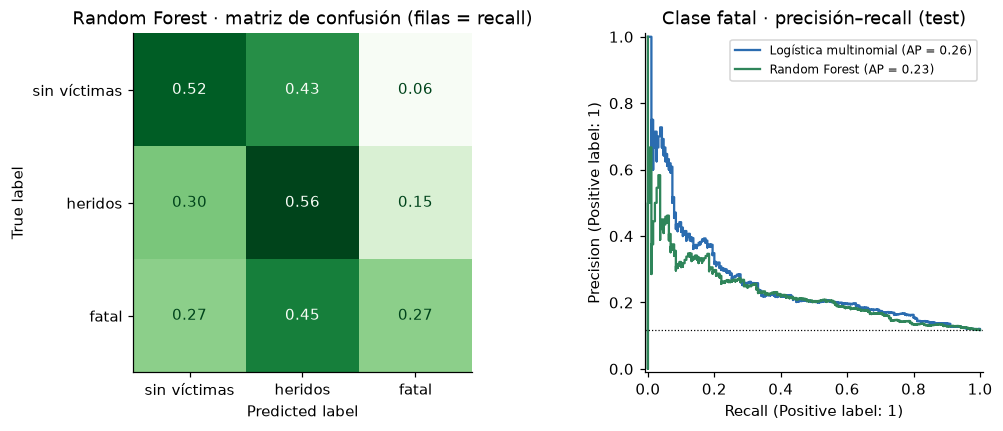

In [10]:
proba_log2 = clone(base2).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
proba_rf2 = clone(rf2).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
hold2 = {"Baseline · Reg. logística multinomial": E.metricas_multiclase(te2.GRAVEDAD, proba_log2),
         "Random Forest (ajustado)": E.metricas_multiclase(te2.GRAVEDAD, proba_rf2)}
display(pd.DataFrame(hold2).T.round(4))
print(classification_report(te2.GRAVEDAD, proba_rf2.argmax(1), target_names=M.CLASES_T2, digits=3))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": "Random Forest (ajustado)", "validacion": "test estratificado 80/20", **hold2["Random Forest (ajustado)"]})

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(te2.GRAVEDAD, proba_rf2.argmax(1), display_labels=M.CLASES_T2, normalize="true",
                                        values_format=".2f", cmap="Greens", ax=axs[0], colorbar=False)
axs[0].set_title("Random Forest · matriz de confusión (filas = recall)")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_log2[:, 2], name="Logística multinomial", ax=axs[1], color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_rf2[:, 2], name="Random Forest", ax=axs[1], color="#2f855a")
axs[1].axhline((te2.GRAVEDAD == 2).mean(), color="k", ls=":", lw=0.8)
axs[1].set_title("Clase fatal · precisión–recall (test)"); axs[1].legend(fontsize=8)
guardar(fig, "modelo_06_t2_rf_test.png")

## 3. Hiperparámetros (Tabla II del informe) y resultados guardados
Se agregan las filas del RF a `results/metrics.csv` (si ya existían, se reemplazan).

In [11]:
print("Espacio de búsqueda: min_samples_leaf, max_features, max_depth (+ class_weight en GRAVEDAD); 20 combinaciones aleatorias")
print("Tarea 1 · N_ACC:    ", config(P1))
print("Tarea 1 · HAY_FATAL:", config(P1b))
print("Tarea 2 · GRAVEDAD: ", config(P2))
f_metrics = ROOT / "results" / "metrics.csv"
nuevas = pd.DataFrame(FILAS)
previas = pd.read_csv(f_metrics)
clave = ["tarea", "modelo", "validacion"]
previas = previas[~previas.set_index(clave).index.isin(nuevas.set_index(clave).index)]
pd.concat([previas, nuevas], ignore_index=True).to_csv(f_metrics, index=False)
print(f"{len(nuevas)} filas guardadas en {f_metrics.name}")
nuevas.round(4)

Espacio de búsqueda: min_samples_leaf, max_features, max_depth (+ class_weight en GRAVEDAD); 20 combinaciones aleatorias
Tarea 1 · N_ACC:     min_samples_leaf=20, max_features=0.2, max_depth=20
Tarea 1 · HAY_FATAL: min_samples_leaf=40, max_features=0.35, max_depth=8
Tarea 2 · GRAVEDAD:  min_samples_leaf=3, max_features=sqrt, max_depth=12, class_weight=balanced_subsample
9 filas guardadas en metrics.csv


,tarea,modelo,validacion,poisson_dev,d2_poisson,mae,rmse,pr_auc,roc_auc,brier,prevalencia,macro_f1,balanced_acc,pr_auc_fatal,log_loss
0,1_conteo_N_ACC,Random Forest (por defecto),CV temporal (5 pliegues),0.9600,0.2495,0.5695,0.7919,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1_conteo_N_ACC,Random Forest (ajustado),CV temporal (5 pliegues),0.9537,0.2544,0.5662,0.7880,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1_conteo_N_ACC,Random Forest (ajustado),holdout abr-sep 2021,0.9799,0.2933,0.6093,0.8366,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1_clasificacion_HAY_FATAL,Random Forest (por defecto),CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1357,0.7094,0.0537,0.0584,NaN,NaN,NaN,NaN
4,1_clasificacion_HAY_FATAL,Random Forest (ajustado),CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1395,0.7162,0.0532,0.0584,NaN,NaN,NaN,NaN
5,1_clasificacion_HAY_FATAL,Random Forest (ajustado),holdout abr-sep 2021,NaN,NaN,NaN,NaN,0.1583,0.7245,0.0602,0.0676,NaN,NaN,NaN,NaN
6,2_triaje_GRAVEDAD,Random Forest (por defecto),CV estratificada 5x5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4562,0.4551,0.2659,0.9613
7,2_triaje_GRAVEDAD,Random Forest (ajustado),CV estratificada 5x5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4519,0.4577,0.2632,0.9798
8,2_triaje_GRAVEDAD,Random Forest (ajustado),test estratificado 80/20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4452,0.4481,0.2266,0.9785


## Lectura
- **Tarea 1 · `N_ACC`:** en la CV temporal el RF empata con el Poisson (D² 0.254 frente a 0.256; −0.002, IC −0.029 a
  +0.025) y supera a la media de 28 días en los 5 pliegues (+0.037). En el **holdout abr–sep 2021 es el mejor modelo
  hasta ahora**: D² 0.293, frente a 0.277 del ingenuo, 0.267 del Poisson y 0.292 del MLP. La figura `modelo_04` muestra
  lo mismo que con el MLP: tras la cuarentena el nivel de accidentes sube y el RF lo sigue mejor que el Poisson en
  Arequipa y Áncash. El MAE no mejora (0.609 frente a 0.590), porque el Poisson predice valores más bajos y el 66 % de
  los días tiene 0 accidentes; por eso la métrica principal es la devianza.
- **Tarea 1 · `HAY_FATAL`:** sin mejora clara. En la CV la PR-AUC sube algo frente a la logística (0.140 frente a 0.133),
  pero gana en 2 de 5 pliegues y el IC incluye el 0; en el holdout queda levemente por debajo (0.158 frente a 0.161).
  Sí supera al ingenuo en los 5 pliegues. Las probabilidades están **bien calibradas** (Brier 0.060, igual que la
  logística; curva de calibración pegada a la diagonal en `modelo_05`), pero no pasan de ≈ 0.2: sirven para ordenar
  departamentos por riesgo, no para anticipar un día fatal concreto.
- **Tarea 2 · `GRAVEDAD`:** el RF es el **primer modelo que supera a la logística en macro-F1**: +0.033 (IC +0.029 a
  +0.036), mejor en los 25 pliegues; también al Modelo 2 del avance (+0.031). La ganancia sale de las clases grandes
  (sin víctimas y heridos); la clase fatal no mejora: PR-AUC fatal igual en la CV (0.263 frente a 0.266) y menor en el
  test (0.227 frente a 0.260), y la balanced accuracy baja 0.008. En el test, recall de fatales 0.27 con precisión
  0.25. El log-loss es mejor que el de la logística (0.98 frente a 1.04), que con pesos balanceados sobrestima la clase
  fatal.
- **Ajuste:** aporta poco. En la Tarea 2 la configuración elegida con `E.CV` dentro del 80 % de entrenamiento
  (`min_samples_leaf=3, max_depth=12`) queda incluso algo por debajo del RF por defecto en la CV 5 × 5 (0.452 frente a
  0.456); se reporta el ajustado, que es el elegido sin mirar el test. Las 5 mejores configuraciones de cada búsqueda
  están a menos de 0.01 entre sí.
- **Conclusión:** las interacciones que captura el árbol ayudan a pronosticar cuántos accidentes habrá (Tarea 1) y a
  separar accidentes con y sin heridos (Tarea 2), pero no a identificar los fatales: ahí el límite está en la
  información del registro, como ya se vio con el MLP.